# Toxic Game Chat Classifier: Classical ML models
**Author: Amogh** | Task: read a game chat message and decide if it is
**0 = neutral/positive**, **1 = negative attitude**, **2 = derogatory**.

How this notebook works: it goes top to bottom. Each section has a short explanation, then code.
Press **Runtime → Run all** and wait about 5 minutes.

## Step 1: Load the data
We have two files from Arvind. `train.csv` is what the model **learns from**. `test.csv` is the **exam**: the model never sees it while learning.
Upload both files when the cell asks (skip if they are already in the Files panel on the left).

In [ ]:
import os
if not (os.path.exists("train.csv") and os.path.exists("test.csv")):
    from google.colab import files
    files.upload()   # choose train.csv and test.csv

## Step 2: Look at the data
Always look before you model. Each row is one chat message with its correct label.

In [2]:
import pandas as pd, re
train = pd.read_csv("train.csv").rename(columns={"comment_text": "message"})
test  = pd.read_csv("test.csv").rename(columns={"comment_text": "message"})
for d in (train, test):
    d["message"] = d["message"].astype(str).str.lower().str.replace(r"http\S+", "", regex=True).str.strip()

print("Training messages:", len(train), "| Test messages:", len(test))
print("Messages per class in train:")
print(train["label"].value_counts().sort_index())
train.head(10)

Training messages: 21120 | Test messages: 6600
Messages per class in train:
label
0    7040
1    7040
2    7040
Name: count, dtype: int64


,message,label
0,we had to tp at the same fucking palce,1
1,lol where is your shrine noob?,1
2,we cant win against this shit,1
3,u two are idiot,2
4,my team retard feed your team retard,2
5,can u stfu and check the ranks,1
6,dont be rude you cunt,2
7,fizz jungle gank more ofthen then u,0
8,talon of shit,1
9,these guys are stupid as shit,2


**What you should say:** the data has 33,000 labelled messages in total, perfectly balanced across the 3 classes.
There are no duplicate messages and no message appears in both train and test, so there is **no data leakage**.

## Step 3: Turn words into numbers (TF-IDF)
Computers cannot read words, only numbers. **TF-IDF** gives every word a score for each message:
high if the word is frequent in that message and rare overall (like "noob"), low if it is common everywhere (like "the").
Tiny example first:

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
demo = TfidfVectorizer()
grid = demo.fit_transform(["gg wp", "you are a noob", "noob noob team"])
pd.DataFrame(grid.toarray().round(2), columns=demo.get_feature_names_out(),
             index=["gg wp", "you are a noob", "noob noob team"])

,are,gg,noob,team,wp,you
gg wp,0.00,0.71,0.00,0.00,0.71,0.00
you are a noob,0.62,0.00,0.47,0.00,0.00,0.62
noob noob team,0.00,0.00,0.84,0.55,0.00,0.00


Now the real thing. **Important rule:** learn the vocabulary from the training data only (`fit_transform`), then just apply it to the test data (`transform`). Otherwise the test set leaks into training.

In [4]:
tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(train["message"])
X_test  = tfidf.transform(test["message"])
y_train, y_test = train["label"].values, test["label"].values
print("Each message is now a row of", X_train.shape[1], "numbers (one per word in the vocabulary)")

Each message is now a row of 7612 numbers (one per word in the vocabulary)


## Step 4: Train and test all the models
Each model is a different "student" learning from the same numbers:
- **SVM** (binary): draws the best dividing line. Here it only decides *neutral vs toxic* (classes 1 and 2 merged).
- **Naive Bayes**: counts how often each word appears in each class and uses probability.
- **KNN**: finds the K most similar training messages and copies their label.
- **Random Forest**: many decision trees that vote.

`fit` = learn from train. `predict` = guess labels for test.

In [5]:
import numpy as np
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix

rows, preds = [], {}
def record(name, y_true, y_pred, labels):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    row = {"model": name, "accuracy": accuracy_score(y_true, y_pred),
           "macro_f1": f1_score(y_true, y_pred, average="macro", labels=labels, zero_division=0)}
    for i, l in enumerate(labels):
        row[f"precision_c{l}"], row[f"recall_c{l}"], row[f"f1_c{l}"] = p[i], r[i], f[i]
    rows.append(row); preds[name] = y_pred
    print(f"{name:40s} accuracy={row['accuracy']:.3f}  macro-F1={row['macro_f1']:.3f}")

### 4a. Binary SVMs (neutral vs toxic)

In [6]:
yb_train = np.where(y_train == 0, 1, -1)   # +1 = neutral, -1 = toxic
yb_test  = np.where(y_test == 0, 1, -1)
for name, kernel in [("SVM linear (binary)", "linear"), ("SVM rbf (binary)", "rbf"), ("SVM poly (binary)", "poly")]:
    m = SVC(kernel=kernel).fit(X_train, yb_train)
    record(name, yb_test, m.predict(X_test), [1, -1])

SVM linear (binary)                      accuracy=0.988  macro-F1=0.987
SVM rbf (binary)                         accuracy=0.987  macro-F1=0.985
SVM poly (binary)                        accuracy=0.956  macro-F1=0.950


### 4b. Baseline Naive Bayes with a hand-made list of toxic words
The paper's baseline only looks at a fixed list of insult words. We build the list from words that appear mostly in classes 1 and 2 in the **training** data, then remove ordinary words by hand.
**You can edit `remove` below** to delete any word that is not really an insult.

In [7]:
from collections import Counter
tok = lambda t: re.findall(r"[a-z']+", t)
c0 = Counter(w for t in train[train.label == 0].message for w in set(tok(t)))
ct = Counter(w for t in train[train.label > 0].message for w in set(tok(t)))
remove = {"you","are","this","your","like","why","what","how","was","only","who","know","because","really",
          "have","with","that","they","just","can","get","for","the","and","not","but","all","from","its","too","when"}
cand = [(w, n) for w, n in ct.items() if n >= 15 and n >= 4 * (c0.get(w, 0) + 1) and len(w) > 2 and w not in remove]
phrases = [w for w, _ in sorted(cand, key=lambda x: -x[1])][:165]
print(len(phrases), "words in the list. First 60:", phrases[:60])

165 words in the list. First 60: ['report', 'team', 'fucking', 'fuck', 'stupid', 'retarded', 'retard', 'shit', 'idiot', 'bitch', 'noob', 'bad', 'feed', 'mother', 'retards', 'trash', 'suck', 'idiots', 'wtf', 'son', 'cunt', 'useless', 'russian', 'mom', 'dick', 'moron', 'fucked', 'think', 'hate', 'dog', 'player', 'faggot', 'easy', 'shut', 'whore', 'his', "you're", 'troll', 'people', 'off', 'cause', 'did', 'stfu', 'russians', 'even', 'cunts', "he's", 'fuckin', 'than', 'such', 'these', 'ass', 'bitches', 'worst', 'yourself', 'nigga', 'lose', 'nigger', 'cuz', 'feeding']


In [8]:
cv = CountVectorizer(vocabulary=phrases)
nb0 = MultinomialNB().fit(cv.transform(train["message"]), y_train)
record("Naive Bayes baseline (word list)", y_test, nb0.predict(cv.transform(test["message"])), [0, 1, 2])

Naive Bayes baseline (word list)         accuracy=0.924  macro-F1=0.923


### 4c. Multiclass models on TF-IDF (0 / 1 / 2). This cell takes about 2 minutes.

In [9]:
models = {
    "Naive Bayes (TF-IDF)": MultinomialNB(),
    "KNN K=1": KNeighborsClassifier(n_neighbors=1),
    "KNN K=2": KNeighborsClassifier(n_neighbors=2),
    "KNN K=3": KNeighborsClassifier(n_neighbors=3),
    "KNN K=6": KNeighborsClassifier(n_neighbors=6),
    "Random Forest (Gini)": RandomForestClassifier(criterion="gini", random_state=42, n_jobs=-1),
    "Random Forest (Entropy)": RandomForestClassifier(criterion="entropy", random_state=42, n_jobs=-1),
    "Random Forest (Entropy, max_depth=32)": RandomForestClassifier(criterion="entropy", max_depth=32, random_state=42, n_jobs=-1),
}
fitted = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    fitted[name] = m
    record(name, y_test, m.predict(X_test), [0, 1, 2])

Naive Bayes (TF-IDF)                     accuracy=0.918  macro-F1=0.917
KNN K=1                                  accuracy=0.738  macro-F1=0.736
KNN K=2                                  accuracy=0.724  macro-F1=0.721
KNN K=3                                  accuracy=0.761  macro-F1=0.757
KNN K=6                                  accuracy=0.794  macro-F1=0.792
Random Forest (Gini)                     accuracy=0.944  macro-F1=0.944
Random Forest (Entropy)                  accuracy=0.942  macro-F1=0.942
Random Forest (Entropy, max_depth=32)    accuracy=0.912  macro-F1=0.911


## Step 5: Results table
**Accuracy** = % of test messages guessed right. **Precision** = when it says "class 2", how often it is right. **Recall** = of all real class 2 messages, how many it found.
**F1** combines the two. **Macro-F1** averages F1 over the 3 classes (fair even if classes are uneven).

In [10]:
results = pd.DataFrame(rows).round(4)
results.to_csv("results.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("MULTICLASS models: accuracy, precision, recall, F1 per class (c0, c1, c2), macro-F1")
multi = results[~results["model"].str.contains("binary")].set_index("model")
display(multi[["accuracy", "precision_c0", "recall_c0", "f1_c0", "precision_c1", "recall_c1", "f1_c1",
               "precision_c2", "recall_c2", "f1_c2", "macro_f1"]])
print("BINARY SVMs (class c1 = neutral, c-1 = toxic)")
display(results[results["model"].str.contains("binary")].set_index("model")[
    ["accuracy", "precision_c1", "recall_c1", "f1_c1", "precision_c-1", "recall_c-1", "f1_c-1", "macro_f1"]])

MULTICLASS models: accuracy, precision, recall, F1 per class (c0, c1, c2), macro-F1


,accuracy,precision_c0,recall_c0,f1_c0,precision_c1,recall_c1,f1_c1,precision_c2,recall_c2,f1_c2,macro_f1
model,,,,,,,,,,,
Naive Bayes baseline (word list),0.9238,0.8664,0.9905,0.9243,0.9623,0.8477,0.9014,0.9562,0.9332,0.9446,0.9234
Naive Bayes (TF-IDF),0.9177,0.9626,0.9477,0.9551,0.9266,0.8436,0.8832,0.8704,0.9618,0.9138,0.9174
KNN K=1,0.7380,0.7366,0.7982,0.7661,0.7135,0.6350,0.6720,0.7609,0.7809,0.7707,0.7363
KNN K=2,0.7241,0.6562,0.9136,0.7638,0.7038,0.6036,0.6499,0.8733,0.6550,0.7486,0.7208
KNN K=3,0.7606,0.7144,0.8700,0.7846,0.7830,0.6118,0.6869,0.7993,0.8000,0.7996,0.7570
KNN K=6,0.7944,0.7580,0.8982,0.8221,0.8106,0.6673,0.7320,0.8245,0.8177,0.8211,0.7917
Random Forest (Gini),0.9439,0.9392,0.9836,0.9609,0.9519,0.8914,0.9207,0.9414,0.9568,0.9491,0.9435
Random Forest (Entropy),0.9423,0.9387,0.9814,0.9596,0.9470,0.8927,0.9190,0.9416,0.9527,0.9471,0.9419
"Random Forest (Entropy, max_depth=32)",0.9124,0.8938,0.9750,0.9326,0.9422,0.8227,0.8784,0.9070,0.9395,0.9230,0.9113


BINARY SVMs (class c1 = neutral, c-1 = toxic)


,accuracy,precision_c1,recall_c1,f1_c1,precision_c-1,recall_c-1,f1_c-1,macro_f1
model,,,,,,,,
SVM linear (binary),0.9885,0.9733,0.9927,0.9829,0.9963,0.9864,0.9913,0.9871
SVM rbf (binary),0.9867,0.9677,0.9932,0.9803,0.9965,0.9834,0.9899,0.9851
SVM poly (binary),0.9564,0.9650,0.9018,0.9323,0.9525,0.9836,0.9678,0.9501


## Step 6: Confusion matrices (every multiclass model)
Rows = the true class, columns = what the model guessed. Numbers on the diagonal are correct. Anything off the diagonal is a mistake.
Each cell shows the count and the % of that true class. These are also saved as `confusion_matrices.png`.

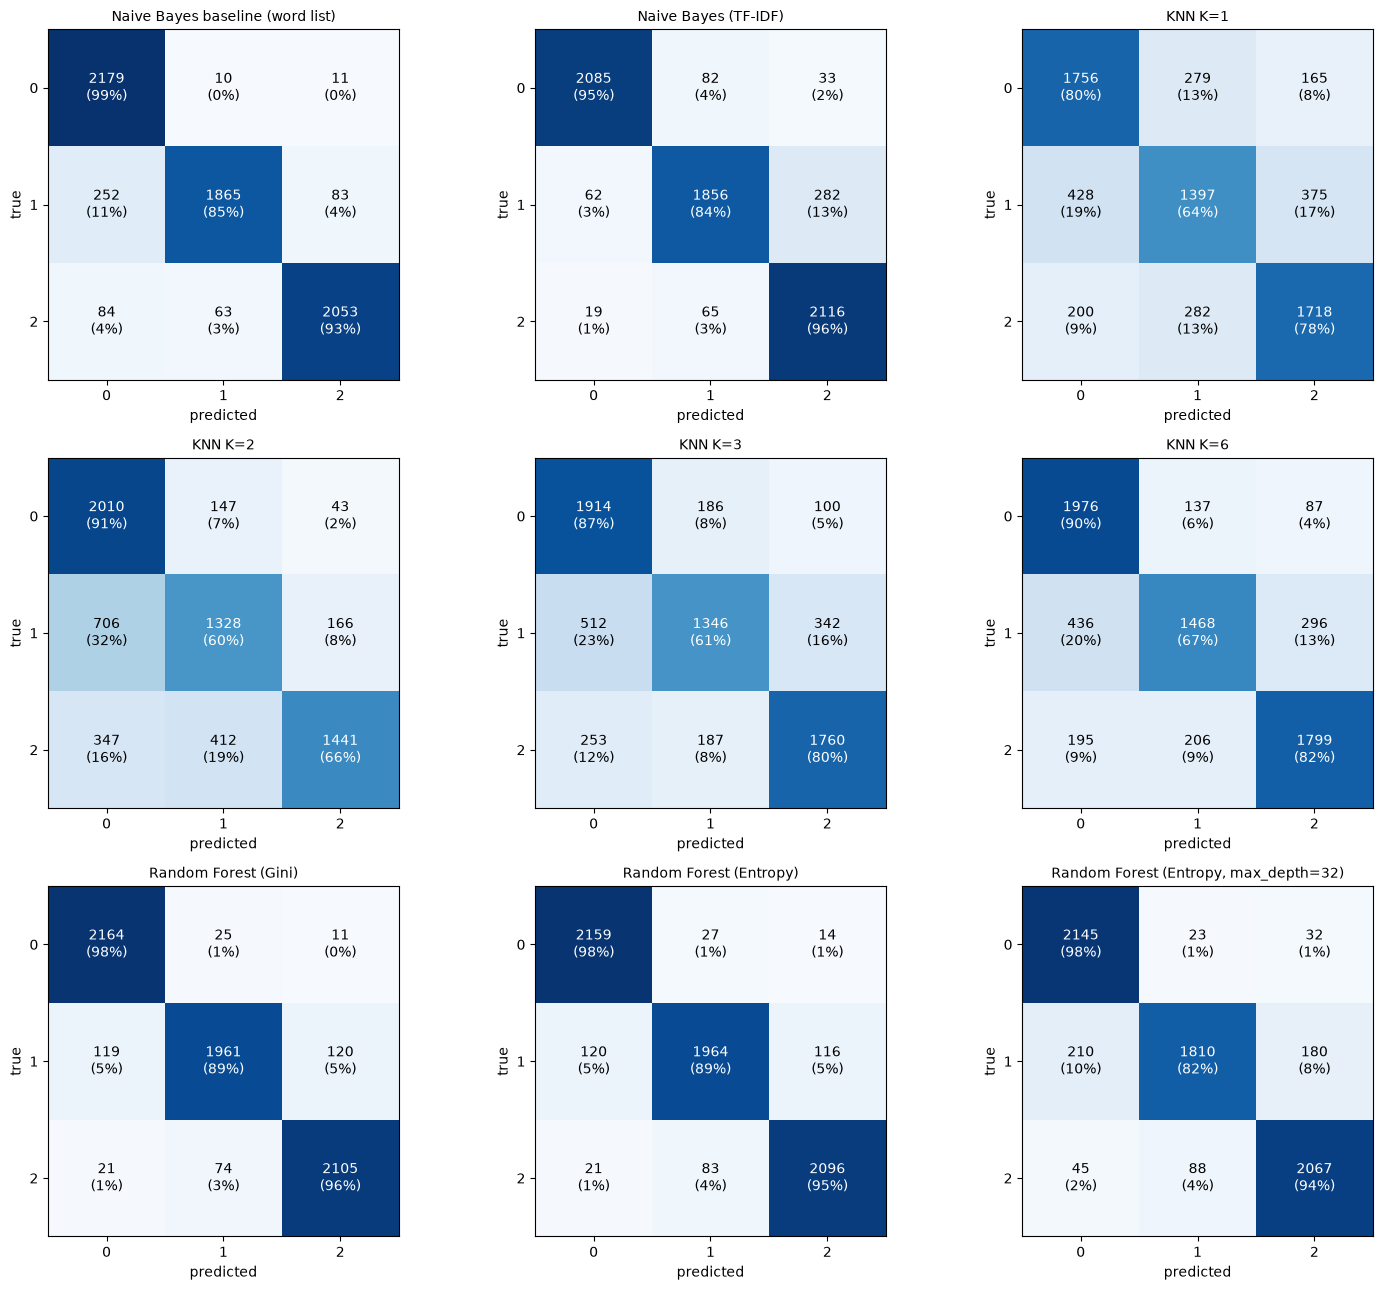

In [11]:
import matplotlib.pyplot as plt
multi_names = [n for n in preds if "binary" not in n]
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for ax, name in zip(axes.ravel(), multi_names):
    cm = confusion_matrix(y_test, preds[name], labels=[0, 1, 2])
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.0%})", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150); plt.show()

## Step 7: Error analysis (where does the model fail, and why?)
We look at real messages that Random Forest got wrong. **Write down the patterns** you notice for your slide.
Typical causes: mild insults sitting between class 1 and class 2, slang or misspellings the model never saw, very short messages with no clear signal, labels that are arguable.

In [12]:
rf = fitted["Random Forest (Gini)"]
wrong = test.assign(predicted=preds["Random Forest (Gini)"])
wrong = wrong[wrong["label"] != wrong["predicted"]]
print(len(wrong), "wrong out of", len(test))
print("\nMost common mix-ups (true -> predicted):")
print(wrong.groupby(["label", "predicted"]).size().sort_values(ascending=False))
pd.set_option("display.max_colwidth", 100)
wrong.sample(20, random_state=1)[["message", "label", "predicted"]]

370 wrong out of 6600

Most common mix-ups (true -> predicted):
label  predicted
1      2            120
       0            119
2      1             74
0      1             25
2      0             21
0      2             11
dtype: int64


,message,label,predicted
3795,i have to fuck all ur mothers,1,2
1486,doesnt help u or me at all,1,0
3516,jug wanted to throw i let him top,1,0
6589,im very sure he dont have a fucking girl in his life,2,1
1174,watch youtube then play like an idiot,1,2
2365,the fuck with this team ,1,2
1950,i play slark as fucking great,0,1
5196,that heart is so fucking good on hero with 1 armor,0,1
4762,ur team unpause the game,0,1
1773,thanks to pl u can talk,1,0


## Step 8: Live demo
Type any chat message and see what the model says. Use this for the presentation.

In [13]:
names = ["0 neutral/positive", "1 negative attitude", "2 derogatory"]
def check(msg):
    p = rf.predict_proba(tfidf.transform([msg.lower()]))[0]
    print(f"{msg!r:45s} -> {names[p.argmax()]}   (confidence {p.max():.0%})")

for m in ["gg well played", "push mid together", "you are so bad noob", "report this feeder", "shut up idiot", "thanks for the carry"]:
    check(m)

'gg well played'                              -> 0 neutral/positive   (confidence 97%)
'push mid together'                           -> 0 neutral/positive   (confidence 97%)
'you are so bad noob'                         -> 1 negative attitude   (confidence 84%)
'report this feeder'                          -> 1 negative attitude   (confidence 96%)
'shut up idiot'                               -> 2 derogatory   (confidence 95%)
'thanks for the carry'                        -> 0 neutral/positive   (confidence 98%)


In [ ]:
# Try your own message here:
check("type your message here")

## Limitations (mention these in your presentation)
- The model only knows words that appeared in training. New slang or deliberate misspellings are ignored.
- Bag-of-words ignores word order and context, so sarcasm is hard.
- The classes were hand-labelled, so some labels are subjective, especially between class 1 and 2.
- KNN scores far lower here than in the original paper because our data has no duplicate messages shared between train and test (the paper's very high KNN score likely came from duplicates).